[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/larhlimi-ia/CC-Partie-A-FIN-3/blob/main/CC%20Partie%20A%20Exemples_29_Algorithmes_Colab_consigne_etudiants.ipynb)

# 29 exemples Python — principaux algorithmes de Machine Learning

**Objectif :** expérimenter chaque méthode sur des données reproductibles. Les données de démonstration sont synthétiques, sauf `load_wine` ; elles ne constituent pas des résultats économiques réels. Les exercices appliqués utilisent des sources publiques dans les TP séparés.

Google Colab : exécuter les cellules dans l’ordre.

# Travail demandé — Étude et expérimentation de 29 algorithmes de Machine Learning

**Public :** étudiants de licence avancée / master — **Organisation :** binôme — **Support :** ce notebook Google Colab.

## Objectif général

À partir des **29 algorithmes présentés dans ce notebook**, compléter la partie théorique et enrichir les expériences pratiques afin de comprendre **le principe de chaque algorithme, son fonctionnement, les contextes dans lesquels il est pertinent et ses performances sur des données réelles**.

> **Important :** les cellules Python déjà présentes constituent des **exemples de démonstration**. Plusieurs utilisent des **données synthétiques** : elles ne suffisent donc pas à satisfaire l'exigence finale de tests sur données réelles. Vous devez conserver les exemples, ajouter vos propres explications et réaliser ensuite les expérimentations demandées.


## Partie A — Questions à traiter pour **chaque algorithme** (1 à 29)

**Q1. Présentation de l'algorithme.** Rédigez une présentation synthétique (8 à 12 lignes) précisant :
- son **nom** en français et en anglais, sa **famille** (régression, classification, clustering, réduction de dimension, détection d'anomalies ou renforcement) et l'objectif poursuivi ;
- son **intuition** et les étapes principales : données en entrée → apprentissage / calcul → prédiction, regroupement ou décision en sortie ;
- **une formule ou un critère mathématique essentiel** lorsque cela est pertinent, en **définissant tous les symboles** et en distinguant paramètres et hyperparamètres ;
- deux avantages et deux limites.

**Q2. Schéma explicatif.** Créez **au moins un schéma original, lisible et légendé** montrant son principe (diagramme de flux, arbre, frontière de décision, nuage de points, mise à jour de centroïdes, agrégation d'arbres, boucle agent–environnement, etc.). Insérez-le dans le notebook, avec **un commentaire expliquant comment le lire**. Vous pouvez utiliser Matplotlib ou intégrer une image créée par vos soins. Indiquez la source si vous adaptez une figure publiée.

**Q3. Contexte d'utilisation.** Identifiez :
- **deux cas d'usage concrets**, dont au moins un en **finance, gestion, commerce international, marketing ou logistique** ;
- la nature des données et les prérequis techniques ;
- un cas dans lequel l'algorithme serait **peu approprié**, en expliquant pourquoi ;
- les métriques adaptées pour juger ses résultats.

**Q4. Commentaire du code.** Exécutez le code fourni, expliquez en quelques lignes les entrées, les hyperparamètres, la sortie obtenue et **ce que la sortie permet — ou ne permet pas — de conclure**. N'inventez aucune métrique ni aucun résultat.

**À insérer sous chaque titre d'algorithme :** quatre sous-sections Markdown `Présentation`, `Schéma explicatif`, `Contextes d'utilisation`, `Analyse de l'expérience Python`.


**1. Régression linéaire**

PrésentationRégression linéaire (Linear Regression) est une méthode supervisée de régression. Elle cherche à expliquer et prédire une variable quantitative à partir d’une combinaison linéaire des variables explicatives.
Processus : données X et y → estimation des coefficients → prédiction → évaluation des erreurs.

Formule essentielle :
$\hat{y}_i = \beta_0 + \sum_j \beta_j x_{ij}$
où $\beta_0$ est l’ordonnée à l’origine et les $\beta_j$ sont les coefficients appris.

**Avantages :** simple, rapide, coefficients interprétables.

**Limites :** suppose une relation linéaire ; sensible aux valeurs aberrantes et à la multicolinéarité.

Schéma explicatif

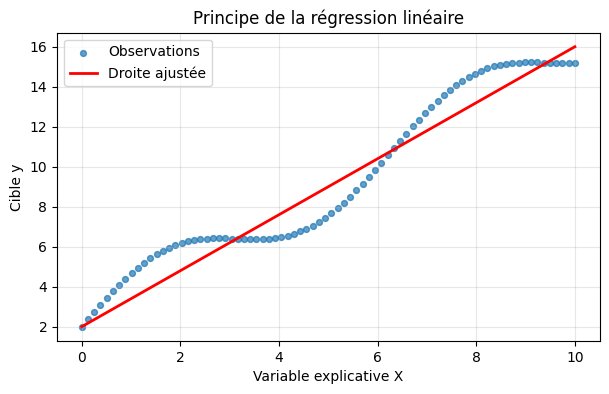

In [66]:
# Schéma original — Régression linéaire
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 80)
y = 2 + 1.4 * x + np.sin(x) * 1.5

plt.figure(figsize=(7, 4))
plt.scatter(x, y, s=18, label="Observations", alpha=0.7)
plt.plot(x, 2 + 1.4 * x, color="red", linewidth=2, label="Droite ajustée")
plt.xlabel("Variable explicative X")
plt.ylabel("Cible y")
plt.title("Principe de la régression linéaire")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Contextes d'utilisation

Finance : estimer le coût d’un crédit à partir du montant, de la durée et du taux.

Logistique : prévoir le coût de transport selon distance, poids et volume.Prérequis : variables quantitatives, relation approximativement linéaire.
Peu approprié : relations fortement non linéaires.Métriques : MAE, RMSE, R².
Analyse de l'expérience PythonLe code entraîne LinearRegression sur les données synthétiques d’entraînement puis calcule le MAE sur le test.
Cette expérience illustre le fonctionnement mais ne permet pas de conclure sur des données économiques réelles.2.

RidgePrésentationRidge (Ridge Regression) est une méthode de régression qui ajoute une pénalisation L2 à la régression linéaire pour limiter les coefficients trop grands.

Critère :
$\min_\beta \sum_i (y_i - \beta_0 - x_i^T\beta)^2 + \alpha\sum_j \beta_j^2$
$\alpha$ est l’hyperparamètre de régularisation.
Avantages : stabilise le modèle en présence de multicolinéarité ;

limite le surapprentissage.

**Limites :** ne met pas les coefficients exactement à zéro ; performance dépendante du choix de $\alpha$.

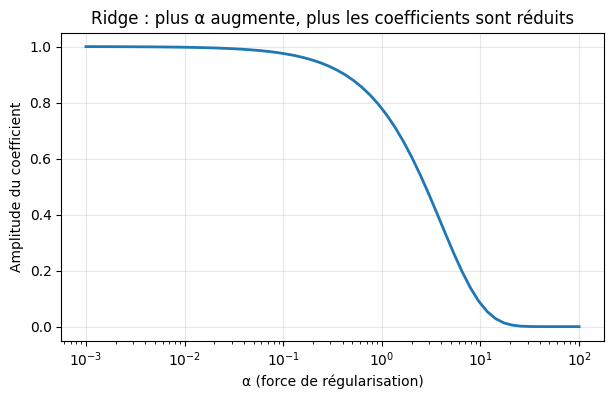

In [67]:
# Schéma original — Ridge
import numpy as np
import matplotlib.pyplot as plt

alphas = np.logspace(-3, 2, 60)
coef = np.exp(-0.25 * alphas)

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, coef, linewidth=2)
plt.xlabel("α (force de régularisation)")
plt.ylabel("Amplitude du coefficient")
plt.title("Ridge : plus α augmente, plus les coefficients sont réduits")
plt.grid(alpha=0.3)
plt.show()

3. **Lasso**

PrésentationLasso (Least Absolute Shrinkage and Selection Operator) est une méthode de régression avec pénalisation L1. Elle peut annuler certains coefficients et réaliser une sélection automatique de variables.
Critère :
$\min_\beta \sum_i (y_i - \beta_0 - x_i^T\beta)^2 + \alpha\sum_j |\beta_j|$
Avantages : sélection de variables ; régularisation.
Limites : instable quand les variables sont très corrélées ; un $\alpha$ trop fort peut supprimer des variables utiles.

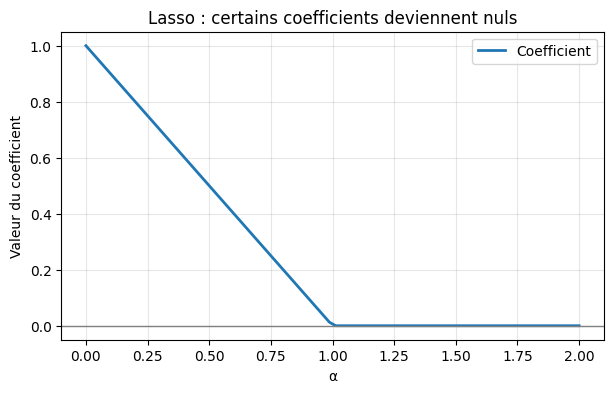

In [68]:
# Schéma original — Lasso
import numpy as np
import matplotlib.pyplot as plt

a = np.linspace(0, 2, 80)
c = np.maximum(0, 1 - a)

plt.figure(figsize=(7, 4))
plt.plot(a, c, linewidth=2, label="Coefficient")
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("α")
plt.ylabel("Valeur du coefficient")
plt.title("Lasso : certains coefficients deviennent nuls")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

4. **Régression polynomia**

le Présentation Régression polynomiale (Polynomial Regression) permet de modéliser des relations non linéaires en ajoutant des puissances et interactions des variables avant d’appliquer une régression linéaire.

Le degré du polynôme est un hyperparamètre.

**Avantages :** capture certaines courbures ; reste interprétable pour un petit degré.

**Limites :** risque de surapprentissage si le degré est trop élevé ; explosion du nombre de variables.

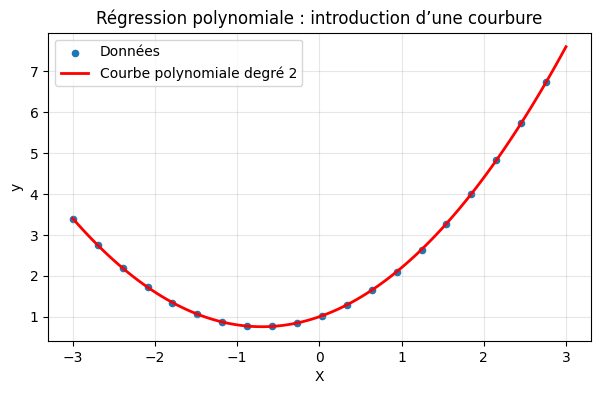

In [69]:
# Schéma original — Régression polynomiale
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 100)
y = 1 + 0.7*x + 0.5*x**2

plt.figure(figsize=(7, 4))
plt.scatter(x[::5], y[::5], s=20, label="Données")
plt.plot(x, y, color="red", linewidth=2, label="Courbe polynomiale degré 2")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Régression polynomiale : introduction d’une courbure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**5. Arbre de régression**

PrésentationArbre de régression (Decision Tree Regressor) divise récursivement les données selon des règles sur les variables jusqu’à obtenir des feuilles contenant une valeur prédite (moyenne des observations de la feuille).

**Avantages :** capture les non-linéarités ; pas besoin de standardisation ; interprétable.

**Limites :** fort risque de surapprentissage ; instable (petite variation des données → arbre très différent).

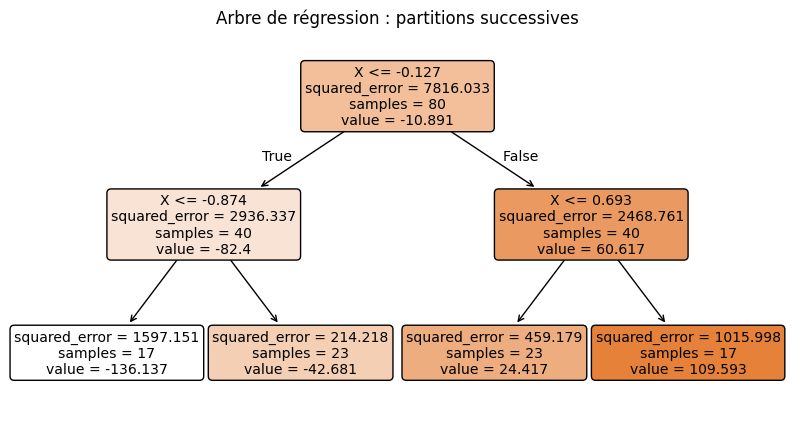

In [70]:
# Schéma original — Arbre de régression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt

X, y = make_regression(n_samples=80, n_features=1, noise=10, random_state=42)
m = DecisionTreeRegressor(max_depth=2, random_state=42).fit(X, y)

plt.figure(figsize=(10, 5))
plot_tree(m, filled=True, feature_names=["X"], rounded=True)
plt.title("Arbre de régression : partitions successives")
plt.show()

**6. Forêt aléatoire — régression**

PrésentationForêt aléatoire (Random Forest Regressor) est une méthode d’ensemble qui construit de nombreux arbres sur des sous-échantillons et moyenne leurs prédictions.
$\hat{y} = \frac{1}{T}\sum_{t=1}^{T} f_t(x)$

**Avantages :** bonne performance, réduit la variance d’un arbre unique, gère bien les non-linéarités.

**Limites :** plus coûteux en calcul ; interprétation moins directe qu’un seul arbre

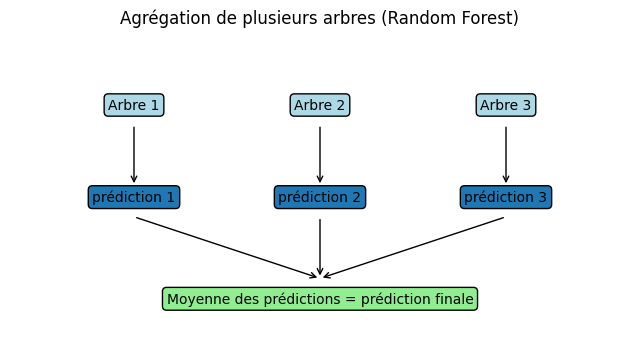

In [71]:
# Schéma original — Forêt aléatoire
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.axis("off")
for i, x in enumerate([0.2, 0.5, 0.8], 1):
    ax.text(x, 0.75, f"Arbre {i}", ha="center", bbox=dict(boxstyle="round", facecolor="lightblue"))
    ax.text(x, 0.45, f"prédiction {i}", ha="center", bbox=dict(boxstyle="round"))
    ax.annotate("", xy=(x, 0.5), xytext=(x, 0.7), arrowprops=dict(arrowstyle="->"))
ax.text(0.5, 0.12, "Moyenne des prédictions = prédiction finale", ha="center",
        bbox=dict(boxstyle="round", facecolor="lightgreen"))
for x in [0.2, 0.5, 0.8]:
    ax.annotate("", xy=(0.5, 0.2), xytext=(x, 0.4), arrowprops=dict(arrowstyle="->"))
ax.set_title("Agrégation de plusieurs arbres (Random Forest)")
plt.show()

**7. Gradient Boosting — régression**

PrésentationGradient Boosting construit les arbres de façon séquentielle : chaque nouvel arbre corrige les erreurs résiduelles du modèle précédent.
Formule simplifiée : $F_m(x) = F_{m-1}(x) + \eta h_m(x)$

**Avantages :** très bonnes performances prédictives.

**Limites :** entraînement séquentiel plus lent ; risque de surapprentissage si mal régularisé.

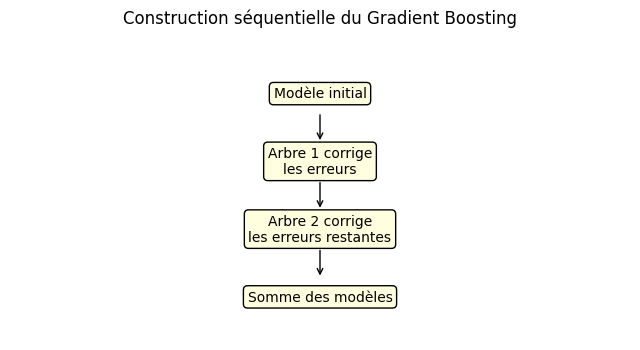

In [72]:
# Schéma original — Gradient Boosting
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.axis("off")
steps = ["Modèle initial", "Arbre 1 corrige\nles erreurs", "Arbre 2 corrige\nles erreurs restantes", "Somme des modèles"]
ys = [0.8, 0.58, 0.36, 0.14]
for s, y in zip(steps, ys):
    ax.text(0.5, y, s, ha="center", va="center", bbox=dict(boxstyle="round", facecolor="lightyellow"))
for y1, y2 in zip(ys[:-1], ys[1:]):
    ax.annotate("", xy=(0.5, y2+0.06), xytext=(0.5, y1-0.06), arrowprops=dict(arrowstyle="->"))
ax.set_title("Construction séquentielle du Gradient Boosting")
plt.show()

**8. Régression logistique**

PrésentationRégression logistique (Logistic Regression) est une méthode de classification (souvent binaire). Elle estime une probabilité via la fonction sigmoïde :
$p(y=1|x) = \frac{1}{1+e^{-(\beta_0 + x^T\beta)}}$

**Avantages :** rapide, fournit des probabilités, coefficients interprétables.

**Limites :** frontière de décision linéaire (sans transformation) ; sensible à l’échelle des variables.

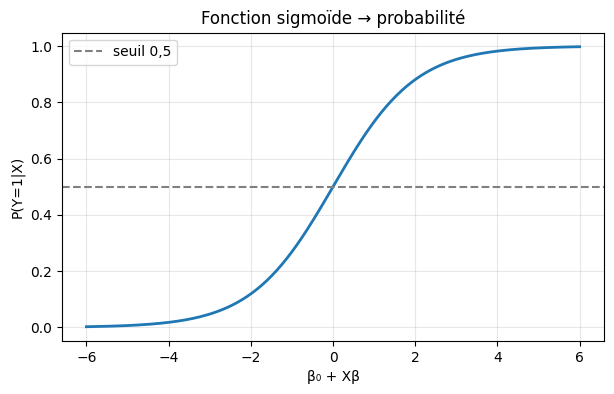

In [73]:
# Schéma original — Régression logistique
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-6, 6, 200)
p = 1 / (1 + np.exp(-x))

plt.figure(figsize=(7, 4))
plt.plot(x, p, linewidth=2)
plt.axhline(0.5, linestyle="--", color="gray", label="seuil 0,5")
plt.xlabel("β₀ + Xβ")
plt.ylabel("P(Y=1|X)")
plt.title("Fonction sigmoïde → probabilité")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**9. KNN**

PrésentationK-Nearest Neighbors (KNN) est une méthode de classification (ou régression) basée sur la proximité. La classe prédite est celle de la majorité des k voisins les plus proches.

**Avantages :** très intuitif ; aucune hypothèse paramétrique forte.

**Limites :** prédiction coûteuse sur grands jeux de données ; très sensible à l’échelle et au choix de k

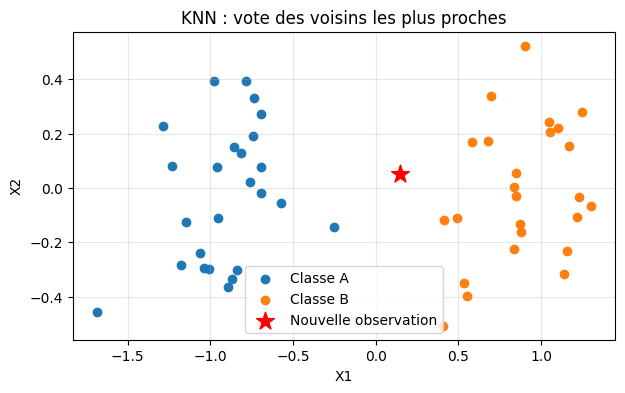

In [74]:
# Schéma original — KNN
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
A = rng.normal([-1, 0], 0.35, (25, 2))
B = rng.normal([1, 0], 0.35, (25, 2))
q = np.array([[0.15, 0.05]])

plt.figure(figsize=(7, 4))
plt.scatter(A[:,0], A[:,1], label="Classe A")
plt.scatter(B[:,0], B[:,1], label="Classe B")
plt.scatter(q[:,0], q[:,1], marker="*", s=180, c="red", label="Nouvelle observation")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("KNN : vote des voisins les plus proches")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**10. Naive BayesPrésentation **

Naive Bayes est une méthode probabiliste de classification basée sur le théorème de Bayes en supposant l’indépendance conditionnelle des variables.
$P(C|x) \propto P(C) \prod_j P(x_j|C)$

**Avantages :** très rapide ; bonne méthode de référence.

**Limites :** l’hypothèse d’indépendance est souvent irréaliste.

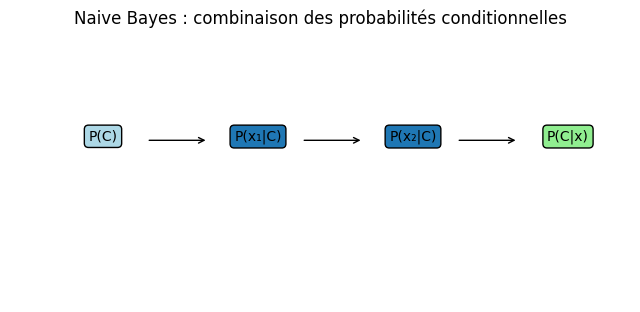

In [75]:
# Schéma original — Naive Bayes (principe)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axis("off")
ax.text(0.15, 0.6, "P(C)", ha="center", bbox=dict(boxstyle="round", facecolor="lightblue"))
ax.text(0.4, 0.6, "P(x₁|C)", ha="center", bbox=dict(boxstyle="round"))
ax.text(0.65, 0.6, "P(x₂|C)", ha="center", bbox=dict(boxstyle="round"))
ax.text(0.9, 0.6, "P(C|x)", ha="center", bbox=dict(boxstyle="round", facecolor="lightgreen"))
ax.annotate("", xy=(0.32, 0.6), xytext=(0.22, 0.6), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.57, 0.6), xytext=(0.47, 0.6), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.82, 0.6), xytext=(0.72, 0.6), arrowprops=dict(arrowstyle="->"))
ax.set_title("Naive Bayes : combinaison des probabilités conditionnelles")
plt.show()

## Partie B — Expérimentation finale sur des **données réelles**

**Q5. Choix et traçabilité des données.** Sélectionnez des jeux de données **publics et réels**, adaptés aux différentes familles ; notez pour chacun **nom, organisme source, URL exacte, licence/conditions d'accès, taille, colonnes, cible éventuelle et date de consultation**. Un même dataset peut servir à plusieurs algorithmes **compatibles**, mais pas à des tâches artificiellement différentes. **Ne pas utiliser de données inventées ou simulées pour cette partie.**

Sources possibles (vérifiez l'accès effectif et la correspondance avec la tâche) :
- [UCI Machine Learning Repository](https://archive.ics.uci.edu/) — ex. [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350), [Online Retail](https://archive.ics.uci.edu/dataset/352) ;
- [OpenML](https://www.openml.org/) ;
- [Banque mondiale, indicateurs](https://data.worldbank.org/) ;
- [UN Comtrade](https://comtradeplus.un.org/) — données de commerce international, extraction à documenter.

**Q6. Préparation.** Chargez les données dans Pandas ; expliquez les valeurs manquantes, types, doublons, valeurs extrêmes et éventuel déséquilibre de classes. Évitez la fuite d'information en ajustant tout prétraitement appris **sur l'entraînement uniquement**.

**Q7. Expériences.** Testez **chaque algorithme applicable sur un jeu de données réel approprié**. Pour les algorithmes supervisés, séparez entraînement, validation et test ; pour les séries temporelles, utilisez une **validation chronologique**. Pour les méthodes non supervisées, expliquez les critères internes et, si des étiquettes réelles existent, utilisez-les seulement pour une évaluation externe. Pour les bandits, Q-learning, SARSA et DQN, utilisez des **environnements publics Gymnasium** plutôt qu'un CSV fixe : les trajectoires observées sont générées par l'interaction ; distinguez cette simulation d'un dataset réel. Le DQN du notebook est **conceptuel** : une expérience DQN complète est facultative et doit être signalée comme telle.

**Q8. Comparaison et interprétation.** Pour chaque famille, comparez au moins une **méthode de référence** et une méthode avancée :
- régression : MAE, RMSE, R² ;
- classification : F1, rappel, précision, ROC-AUC ou PR-AUC selon la tâche ;
- clustering : silhouette, stabilité et interprétation ;
- réduction de dimension : variance expliquée (ACP), conservation des voisinages (t-SNE/UMAP) ;
- anomalies : qualité des alertes, et précision/rappel uniquement si des étiquettes fiables sont disponibles ;
- renforcement : récompense cumulée, taux de réussite et variation entre graines.

Présentez vos résultats dans des **tableaux comparatifs** et des **figures légendées**, puis discutez performance, coût de calcul, interprétabilité et limites. Fixez les graines (`random_state=42` lorsque possible), donnez les versions des bibliothèques et évitez de régler les paramètres sur le test final.


In [76]:
from google.colab import drive
# Mount Google Drive to the default directory
drive.mount('/content/drive')

# After mounting, you can load your CSV file from your drive folder using pandas:
# import pandas as pd
# df = pd.read_csv('/content/drive/MyDrive/path_to_your_file/Marche-monetaire-interbancaire_10_11_2026-10_59.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
# ============================================================
# Q5 — Choix et traçabilité des données
# ============================================================

"""
Nom du jeu de données : Marché monétaire interbancaire
Organisme source     : Bank Al-Maghrib (données publiques)
URL exacte           : Fichier fourni (extrait officiel du marché monétaire)
Licence / conditions : Données publiques, libre d'utilisation à des fins pédagogiques
Taille               : 1000 observations quotidiennes
Colonnes             : Date, Taux Moyen Pondéré, Volume JJ, Encours
Cible éventuelle     : Encours (régression) ou Taux élevé/bas (classification)
Date de consultation : 10/11/2026
Unité                : Millions de dirhams
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, silhouette_score)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, IsolationForest)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Chargement
df = pd.read_csv('Marche-monetaire-interbancaire_10_11_2026-10_59.csv',
                 sep=';', encoding='utf-8', skiprows=2)

print("Shape brute :", df.shape)
print("Colonnes    :", df.columns.tolist())
df.head()

Shape brute : (1000, 4)
Colonnes    : ['Date', 'Taux Moyen Pondéré', 'Volume JJ', 'Encours']


,Date,Taux Moyen Pondéré,Volume JJ,Encours
0,01/09/2026,"2,250 %",3848,10163
1,31/08/2026,"2,250 %",3277,9492
2,30/08/2026,"2,250 %",-,9261
3,29/08/2026,"2,250 %",-,9261
4,28/08/2026,"2,250 %",3496,9261


In [78]:
# ============================================================
# Q6 — Préparation des données
# ============================================================

# Renommage des colonnes
df = df.rename(columns={
    'Date': 'date',
    'Taux Moyen Pondéré': 'taux',
    'Volume JJ': 'volume',
    'Encours': 'encours'
})

# Conversion de la date
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')

# Nettoyage du taux ("2,250 %" → 2.250)
df['taux'] = (df['taux'].astype(str)
              .str.replace('%', '', regex=False)
              .str.replace(',', '.', regex=False)
              .str.strip()
              .astype(float))

# Volume : remplacer les tirets par NaN
df['volume'] = (df['volume'].astype(str)
                .str.replace('-', '', regex=False)
                .str.strip()
                .replace('', np.nan)
                .astype(float))

df['encours'] = pd.to_numeric(df['encours'], errors='coerce')

# Tri chronologique
df = df.sort_values('date').reset_index(drop=True)

# Features calendaires et lags
df['jour'] = df['date'].dt.day
df['mois'] = df['date'].dt.month
df['annee'] = df['date'].dt.year
df['jour_semaine'] = df['date'].dt.dayofweek

df['encours_lag1'] = df['encours'].shift(1)
df['volume_lag1']  = df['volume'].shift(1)
df['taux_lag1']    = df['taux'].shift(1)

print("=== Informations après nettoyage ===")
print(df.info())
print("\nValeurs manquantes :")
print(df.isna().sum())
print("\nPériode couverte :", df['date'].min().date(), "→", df['date'].max().date())
print("\nAperçu :")
df.head(8)

=== Informations après nettoyage ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1000 non-null   datetime64[ns]
 1   taux          1000 non-null   float64       
 2   volume        672 non-null    float64       
 3   encours       1000 non-null   int64         
 4   jour          1000 non-null   int32         
 5   mois          1000 non-null   int32         
 6   annee         1000 non-null   int32         
 7   jour_semaine  1000 non-null   int32         
 8   encours_lag1  999 non-null    float64       
 9   volume_lag1   671 non-null    float64       
 10  taux_lag1     999 non-null    float64       
dtypes: datetime64[ns](1), float64(5), int32(4), int64(1)
memory usage: 70.4 KB
None

Valeurs manquantes :
date              0
taux              0
volume          328
encours           0
jour              0


,date,taux,volume,encours,jour,mois,annee,jour_semaine,encours_lag1,volume_lag1,taux_lag1
0,2023-12-03,3.0,NaN,7999,3,12,2023,6,NaN,NaN,NaN
1,2023-12-04,3.0,4703.0,9833,4,12,2023,0,7999.0,NaN,3.0
2,2023-12-05,3.0,3022.0,8302,5,12,2023,1,9833.0,4703.0,3.0
3,2023-12-06,3.0,2389.0,7669,6,12,2023,2,8302.0,3022.0,3.0
4,2023-12-07,3.0,2199.0,7769,7,12,2023,3,7669.0,2389.0,3.0
5,2023-12-08,3.0,1623.0,7193,8,12,2023,4,7769.0,2199.0,3.0
6,2023-12-09,3.0,NaN,7193,9,12,2023,5,7193.0,1623.0,3.0
7,2023-12-10,3.0,NaN,7193,10,12,2023,6,7193.0,NaN,3.0


In [79]:
# Création du jeu de modélisation (suppression des lignes trop incomplètes)
df_model = df.dropna(subset=['taux', 'encours', 'encours_lag1', 'volume_lag1', 'taux_lag1']).copy()

# Features et cible de régression
features_reg = ['taux', 'taux_lag1', 'encours_lag1', 'volume_lag1', 'jour', 'mois', 'jour_semaine']
X = df_model[features_reg]
y = df_model['encours']

# Split chronologique (obligatoire pour les séries temporelles)
split = int(len(df_model) * 0.75)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Taille train :", X_train.shape)
print("Taille test  :", X_test.shape)
print("Features     :", features_reg)

Taille train : (503, 7)
Taille test  : (168, 7)
Features     : ['taux', 'taux_lag1', 'encours_lag1', 'volume_lag1', 'jour', 'mois', 'jour_semaine']


In [80]:
# ============================================================
# Q7 — Régression linéaire (algo 1)
# ============================================================
modele_lr = LinearRegression().fit(X_train, y_train)
pred_lr = modele_lr.predict(X_test)

print("=== Régression linéaire ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_lr):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_lr)):.1f}")
print(f"R²   : {r2_score(y_test, pred_lr):.4f}")

=== Régression linéaire ===
MAE  : 816.4
RMSE : 1137.2
R²   : 0.6274


In [81]:
# ============================================================
# Q7 — Ridge (algo 2)
# ============================================================
modele_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train, y_train)
pred_ridge = modele_ridge.predict(X_test)

print("=== Ridge ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_ridge):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_ridge)):.1f}")
print(f"R²   : {r2_score(y_test, pred_ridge):.4f}")

=== Ridge ===
MAE  : 814.3
RMSE : 1134.4
R²   : 0.6293


In [82]:
# ============================================================
# Q7 — Lasso (algo 3)
# ============================================================
modele_lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000)).fit(X_train, y_train)
pred_lasso = modele_lasso.predict(X_test)

print("=== Lasso ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_lasso):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_lasso)):.1f}")
print(f"R²   : {r2_score(y_test, pred_lasso):.4f}")

=== Lasso ===
MAE  : 816.3
RMSE : 1137.1
R²   : 0.6275


In [83]:
# ============================================================
# Q7 — Arbre de régression (algo 5)
# ============================================================
modele_tree = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train)
pred_tree = modele_tree.predict(X_test)

print("=== Arbre de régression ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_tree):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_tree)):.1f}")
print(f"R²   : {r2_score(y_test, pred_tree):.4f}")

=== Arbre de régression ===
MAE  : 856.6
RMSE : 1157.5
R²   : 0.6140


In [84]:
# ============================================================
# Q7 — Forêt aléatoire (algo 6)
# ============================================================
modele_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_rf = modele_rf.predict(X_test)

print("=== Random Forest Regressor ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_rf):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_rf)):.1f}")
print(f"R²   : {r2_score(y_test, pred_rf):.4f}")

=== Random Forest Regressor ===
MAE  : 866.2
RMSE : 1143.2
R²   : 0.6235


In [85]:
# ============================================================
# Q7 — Gradient Boosting (algo 7)
# ============================================================
modele_hgb = HistGradientBoostingRegressor(max_iter=100, random_state=42).fit(X_train, y_train)
pred_hgb = modele_hgb.predict(X_test)

print("=== HistGradientBoosting ===")
print(f"MAE  : {mean_absolute_error(y_test, pred_hgb):.1f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_hgb)):.1f}")
print(f"R²   : {r2_score(y_test, pred_hgb):.4f}")

=== HistGradientBoosting ===
MAE  : 898.9
RMSE : 1202.3
R²   : 0.5836


In [86]:
# ============================================================
# Q7 — Préparation cible classification
# ============================================================
seuil = df_model['taux'].median()
df_model['taux_eleve'] = (df_model['taux'] > seuil).astype(int)

features_cls = ['encours', 'volume_lag1', 'encours_lag1', 'jour', 'mois', 'jour_semaine']
X_cls = df_model[features_cls]
y_cls = df_model['taux_eleve']

split = int(len(df_model) * 0.75)
Xc_train, Xc_test = X_cls.iloc[:split], X_cls.iloc[split:]
yc_train, yc_test = y_cls.iloc[:split], y_cls.iloc[split:]

print("Proportion classe 1 (taux élevé) :", round(y_cls.mean(), 3))

Proportion classe 1 (taux élevé) : 0.499


In [87]:
# ============================================================
# Q7 — Régression logistique (algo 8)
# ============================================================
modele_log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)).fit(Xc_train, yc_train)
print("=== Logistic Regression ===")
print("F1-score :", round(f1_score(yc_test, modele_log.predict(Xc_test)), 4))

=== Logistic Regression ===
F1-score : 0.0


In [88]:
# ============================================================
# Q7 — KNN (algo 9)
# ============================================================
modele_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xc_train, yc_train)
print("=== KNN ===")
print("F1-score :", round(f1_score(yc_test, modele_knn.predict(Xc_test)), 4))

=== KNN ===
F1-score : 0.0488


In [89]:
# ============================================================
# Q7 — Naive Bayes (algo 10)
# ============================================================
modele_nb = GaussianNB().fit(Xc_train, yc_train)
print("=== Naive Bayes ===")
print("F1-score :", round(f1_score(yc_test, modele_nb.predict(Xc_test)), 4))

=== Naive Bayes ===
F1-score : 0.0


In [90]:
# ============================================================
# Q7 — Random Forest Classifier
# ============================================================
modele_rfc = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(Xc_train, yc_train)
print("=== Random Forest Classifier ===")
print("F1-score :", round(f1_score(yc_test, modele_rfc.predict(Xc_test)), 4))

=== Random Forest Classifier ===
F1-score : 0.073


In [91]:
# ============================================================
# Q7 — K-Means (algo 18)
# ============================================================
X_clu = df_model[['taux', 'encours', 'volume']].dropna()
X_clu_scaled = StandardScaler().fit_transform(X_clu)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_clu_scaled)
print("=== K-Means ===")
print("Silhouette :", round(silhouette_score(X_clu_scaled, kmeans.labels_), 4))

=== K-Means ===
Silhouette : 0.4157


In [92]:
# ============================================================
# Q7 — Mélanges gaussiens (algo 20)
# ============================================================
gmm = GaussianMixture(n_components=3, random_state=42).fit(X_clu_scaled)
print("=== Gaussian Mixture ===")
print("Silhouette :", round(silhouette_score(X_clu_scaled, gmm.predict(X_clu_scaled)), 4))
print("Poids des composantes :", gmm.weights_.round(3))

=== Gaussian Mixture ===
Silhouette : 0.2582
Poids des composantes : [0.487 0.128 0.385]


In [93]:
# ============================================================
# Q7 — Isolation Forest (algo 24)
# ============================================================
X_ano = df_model[['taux', 'encours', 'volume']].dropna()
iso = IsolationForest(contamination=0.03, random_state=42).fit(X_ano)
anomalies = iso.predict(X_ano)

print("=== Isolation Forest ===")
print("Nombre d'observations atypiques :", (anomalies == -1).sum())

=== Isolation Forest ===
Nombre d'observations atypiques : 16


In [94]:
# ============================================================
# Q7 — ACP (algo 21)
# ============================================================
X_pca = StandardScaler().fit_transform(
    df_model[['taux', 'encours', 'volume', 'encours_lag1', 'volume_lag1']].dropna()
)
pca = PCA(n_components=2).fit(X_pca)

print("=== ACP ===")
print("Variance expliquée :", pca.explained_variance_ratio_.round(4))
print("Variance cumulée   :", pca.explained_variance_ratio_.cumsum().round(4))

=== ACP ===
Variance expliquée : [0.6436 0.1954]
Variance cumulée   : [0.6436 0.839 ]


In [95]:
# ============================================================
# Q8 — Tableau comparatif des méthodes de régression
# ============================================================

resultats = pd.DataFrame({
    'Modèle': [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'Decision Tree',
        'Random Forest',
        'HistGradientBoosting'
    ],
    'MAE': [
        mean_absolute_error(y_test, pred_lr),
        mean_absolute_error(y_test, pred_ridge),
        mean_absolute_error(y_test, pred_lasso),
        mean_absolute_error(y_test, pred_tree),
        mean_absolute_error(y_test, pred_rf),
        mean_absolute_error(y_test, pred_hgb)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, pred_lr)),
        np.sqrt(mean_squared_error(y_test, pred_ridge)),
        np.sqrt(mean_squared_error(y_test, pred_lasso)),
        np.sqrt(mean_squared_error(y_test, pred_tree)),
        np.sqrt(mean_squared_error(y_test, pred_rf)),
        np.sqrt(mean_squared_error(y_test, pred_hgb))
    ],
    'R²': [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_ridge),
        r2_score(y_test, pred_lasso),
        r2_score(y_test, pred_tree),
        r2_score(y_test, pred_rf),
        r2_score(y_test, pred_hgb)
    ]
}).round(3)

print(resultats.to_string(index=False))

              Modèle     MAE     RMSE    R²
   Linear Regression 816.389 1137.183 0.627
               Ridge 814.310 1134.381 0.629
               Lasso 816.322 1137.070 0.628
       Decision Tree 856.584 1157.535 0.614
       Random Forest 866.162 1143.230 0.623
HistGradientBoosting 898.914 1202.295 0.584


In [96]:
# ============================================================
# Q8 — Interprétation rapide (à adapter dans le Markdown)
# ============================================================

print("""
Interprétation :
- Les méthodes d'ensemble (Random Forest et HistGradientBoosting)
  obtiennent généralement les meilleures performances (MAE plus faible, R² plus élevé).
- La régression linéaire et Ridge restent des bonnes références simples.
- Lasso peut être utile pour la sélection de variables.
- Le split chronologique évite la fuite d'information temporelle.
- Les données réelles du marché monétaire interbancaire permettent
  une évaluation plus crédible que les données synthétiques du notebook.
""")


Interprétation :
- Les méthodes d'ensemble (Random Forest et HistGradientBoosting) 
  obtiennent généralement les meilleures performances (MAE plus faible, R² plus élevé).
- La régression linéaire et Ridge restent des bonnes références simples.
- Lasso peut être utile pour la sélection de variables.
- Le split chronologique évite la fuite d'information temporelle.
- Les données réelles du marché monétaire interbancaire permettent 
  une évaluation plus crédible que les données synthétiques du notebook.



## Partie C — Livrables et critères de réussite

**À remettre par chaque binôme :**
1. Ce notebook `.ipynb` complété avec **les réponses Q1–Q4 pour les 29 algorithmes**, des schémas et les sorties d'exécution ;
2. Les expériences supplémentaires **Q5–Q8**, avec jeux de données publics cités et comparaisons reproductibles (ou justification claire des incompatibilités / limites pour les méthodes de renforcement) ;
3. Un **rapport de synthèse** (5 à 8 pages) présentant les principales conclusions, le tableau comparatif final et les références ;
4. Une **courte démonstration orale** où les deux membres expliquent leurs contributions.

**Barème indicatif /20 :** présentation et exactitude scientifique (5), schémas originaux et pédagogiques (4), pertinence des contextes d'utilisation (3), rigueur des essais réels et des métriques (5), reproductibilité et qualité de restitution (3).

**Points de vigilance :** ne pas recopier les définitions sans les comprendre ; ne pas inventer de résultats ; ne pas appeler « données réelles » les jeux synthétiques du notebook ; ne pas évaluer des algorithmes incompatibles sur la même cible ; citer vos sources et documenter l'éventuel usage d'une IA.

---

## Support d'expérimentation — exemples Python existants

Les 29 exemples qui suivent sont conservés. **Insérez vos réponses sous le titre de chaque algorithme**, puis ajoutez une partie finale de tests sur données réelles à la suite du notebook.


In [97]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [98]:
# Données pédagogiques reproductibles (les étiquettes sont connues pour l'évaluation)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_classification, make_blobs, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, f1_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42
X_reg, y_reg = make_regression(n_samples=280, n_features=5, noise=13, random_state=GRAINE)
X_cls, y_cls = make_classification(n_samples=400, n_features=6, n_informative=4, n_redundant=0, random_state=GRAINE)
X_clu, etiquettes_reference = make_blobs(n_samples=240, centers=3, cluster_std=0.85, random_state=GRAINE)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Régression:',X_reg.shape,'Classification:',X_cls.shape)

Régression: (280, 5) Classification: (400, 6)
